# RevPulse data quality and exploratory analysis

Synthetic SaaS data. Monetary source fields are integer paise. Invoicing, collections and MRR are separate metrics. No causal conclusions are drawn.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from revpulse.core import current_run
root=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
run=current_run(root)
print('Run:',run.name)


Run: 20261107T082251_ebe78748


In [2]:
quality=json.loads((run/'audit/quality.json').read_text())
pd.DataFrame(quality['tables']).T

,input,accepted,duplicate,quarantined
customers,1000,1000,0,0
subscription_periods,3223,3223,0,0
invoices,15441,15435,1,5
payment_events,17697,17693,0,4
customer_monthly_activity,22124,22123,0,1


In [3]:
pd.read_csv(run/'audit/transformations.csv')

,table,key,field,original,replacement,rule
0,customers,C0001,region,west-india,West,region_mapping
1,invoices,C0001-P2-202305,total_paise,NaN,590000,authoritative_components


In [4]:
pd.read_csv(run/'quarantine/records.csv')[['table','key','reason']].head(15)

,table,key,reason
0,invoices,C0001-P2-202306,invoice_component_mismatch
1,invoices,C0001-P2-202307,conflicting_key
2,invoices,C0001-P2-202307,conflicting_key
3,invoices,C0001-ADD-202307,orphan_customer
4,invoices,C0001-P2-202308,invalid_iso_date:issue_date
5,payment_events,C0001-P2-202306-PAY,orphan_invoice
6,payment_events,C0001-P2-202307-PAY,orphan_invoice
7,payment_events,C0001-ADD-202307-PAY,orphan_invoice
8,payment_events,C0001-P2-202308-PAY,orphan_invoice
9,customer_monthly_activity,C0001-202304,invalid_usage


## Financial controls
The SQL totals below are reconciled against independent Python arithmetic. Annual charges are normalized for MRR; taxes and one-time fees stay in invoicing.

In [5]:
json.loads((run/'audit/reconciliation.json').read_text())

{'checks': {'invoice_total': True,
  'collections_total': True,
  'mrr_bridge': True,
  'month_end_mrr': True,
  'distinct_active_accounts': True,
  'balance_identity': True},
 'invoiced_paise': 16343289600,
 'net_collections_paise': 15390947680,
 'closing_mrr_paise': '362290000',
 'active_accounts': 651}

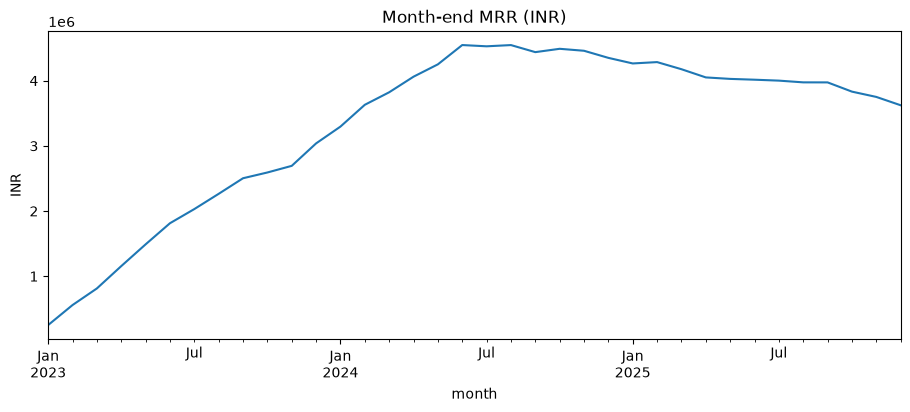

In [6]:
monthly=pd.read_csv(run/'marts/mart_revenue_month.csv')
ax=monthly.assign(month=pd.to_datetime(monthly.month),mrr_inr=monthly.closing_mrr_paise/100).plot(x='month',y='mrr_inr',figsize=(11,4),legend=False,title='Month-end MRR (INR)'); ax.set_ylabel('INR'); plt.show()

In [7]:
pd.read_csv(run/'queries/regional_channel_performance.csv')

,region,acquisition_channel,mrr_paise,active_accounts,arpa_paise,invoiced_paise,collections_paise,payment_attempt_failure_rate
0,South,Referral,37080000.0,48,772500.000000,1338940100,1246478250,0.111200
1,South,LinkedIn Ads,23350000.0,33,707575.757576,944005900,877744180,0.111965
2,North,Organic,15520000.0,38,408421.052632,930595200,849158680,0.102900
3,East,Cold Email,31100000.0,53,586792.452830,1119867200,1053527600,0.113360
4,East,Referral,22730000.0,41,554390.243902,1051616000,972771350,0.105860
5,South,Cold Email,21740000.0,36,603888.888889,976414600,939436350,0.110471
6,East,LinkedIn Ads,13800000.0,44,313636.363636,926199700,873469630,0.093750
7,North,Referral,20390000.0,34,599705.882353,750485900,697788280,0.102719
8,South,Organic,28010000.0,49,571632.653061,1355973400,1283294250,0.101507
9,West,Referral,25750000.0,36,715277.777778,982184800,896440100,0.095420


## Billing investigation
IQR flags compare plan and billing-interval peers. A statistical flag does not establish a billing error. Sparse groups and zero-IQR groups are skipped. Contract mismatches use explicit invoice-versus-contract checks.

In [8]:
pd.read_csv(run/'analytics/billing_anomalies.csv').head(15)

,record_id,customer_id,rule,observed_paise,expected_paise,severity,review_status
0,C0001-ADD-202308,C0001,contract_charge_mismatch,80000,50000.0,High,Open
1,C0001-ADD-202309,C0001,peer_group_iqr,50000,115000.0,Review,Open
2,C0001-ADD-202310,C0001,peer_group_iqr,50000,115000.0,Review,Open
3,C0001-ADD-202311,C0001,peer_group_iqr,50000,115000.0,Review,Open
4,C0001-ADD-202312,C0001,peer_group_iqr,50000,115000.0,Review,Open
5,C0001-ADD-202401,C0001,peer_group_iqr,50000,115000.0,Review,Open
6,C0001-ADD-202402,C0001,peer_group_iqr,50000,115000.0,Review,Open
7,C0001-ADD-202403,C0001,peer_group_iqr,50000,115000.0,Review,Open
8,C0001-ADD-202404,C0001,peer_group_iqr,50000,115000.0,Review,Open
9,C0001-ADD-202405,C0001,peer_group_iqr,50000,115000.0,Review,Open


In [9]:
json.loads((run/'analytics/defect_evaluation.json').read_text())

{'injected': [{'table': 'invoices',
   'key': 'C0001-P1-202304',
   'kind': 'exact_duplicate',
   'quarantined': False,
   'duplicate_detected': True,
   'anomaly_flagged': False,
   'transformed': False,
   'handled': True},
  {'table': 'invoices',
   'key': 'C0001-P2-202305',
   'kind': 'recoverable_missing',
   'quarantined': False,
   'duplicate_detected': False,
   'anomaly_flagged': False,
   'transformed': True,
   'handled': True},
  {'table': 'invoices',
   'key': 'C0001-P2-202306',
   'kind': 'invoice_mismatch',
   'quarantined': True,
   'duplicate_detected': False,
   'anomaly_flagged': False,
   'transformed': False,
   'handled': True},
  {'table': 'invoices',
   'key': 'C0001-P2-202307',
   'kind': 'conflicting_key',
   'quarantined': True,
   'duplicate_detected': False,
   'anomaly_flagged': False,
   'transformed': False,
   'handled': True},
  {'table': 'invoices',
   'key': 'C0001-ADD-202307',
   'kind': 'orphan_customer',
   'quarantined': True,
   'duplicate_detec

## Exploratory hypothesis
At one fixed month, do accounts that churn during the following month have different recent payment delays? Using one snapshot avoids treating repeated customer-months as independent observations. This is observational and exploratory, with no causal interpretation.

Fixed snapshot: 2025-06-30 accounts: 720


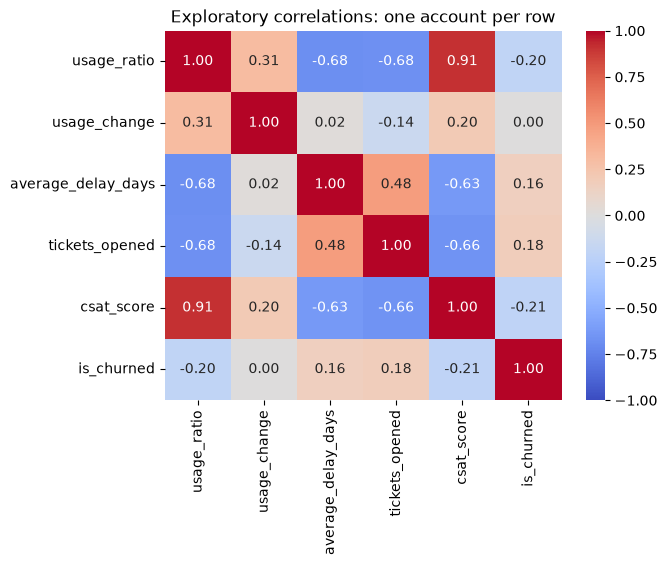

In [10]:
features=pd.read_csv(run/'analytics/customer_features.csv')
observed=features[features.is_churned.notna()]
dates=sorted(observed.score_date.unique()); snapshot=observed[observed.score_date==dates[-6]].copy()
print('Fixed snapshot:',dates[-6], 'accounts:',len(snapshot))
sns.heatmap(snapshot[['usage_ratio','usage_change','average_delay_days','tickets_opened','csat_score','is_churned']].corr(),annot=True,fmt='.2f',vmin=-1,vmax=1,cmap='coolwarm'); plt.title('Exploratory correlations: one account per row'); plt.show()

In [11]:
from scipy.stats import mannwhitneyu
a=snapshot.loc[snapshot.is_churned==1,'average_delay_days'].dropna().to_numpy()
b=snapshot.loc[snapshot.is_churned==0,'average_delay_days'].dropna().to_numpy()
if len(a) and len(b):
    result=mannwhitneyu(a,b,alternative='two-sided')
    rng=np.random.default_rng(42)
    boot=[np.median(rng.choice(a,len(a)))-np.median(rng.choice(b,len(b))) for _ in range(1000)]
    finding={'churned_n':len(a),'retained_n':len(b),'median_delay_difference_days':float(np.median(a)-np.median(b)),'bootstrap_95pct_interval':np.quantile(boot,[.025,.975]).tolist(),'mann_whitney_p':float(result.pvalue),'rank_biserial_effect':float(2*result.statistic/(len(a)*len(b))-1)}
    (run/'analytics/hypothesis_result.json').write_text(json.dumps(finding,indent=2))
    display(finding)
else:
    print('Insufficient observed classes; no test reported.')

{'churned_n': 11,
 'retained_n': 494,
 'median_delay_difference_days': 8.25,
 'bootstrap_95pct_interval': [4.497916666666667, 24.25],
 'mann_whitney_p': 0.0018979639799565492,
 'rank_biserial_effect': 0.5472948104527051}

Missing delay values are excluded from the hypothesis test and their counts remain visible in the sample sizes. The bootstrap resamples accounts within outcome groups. Simulation assumptions and a single chosen month limit generalization.